## Упражнения

Мы рассмотрим набор данных [Libras](https://www.timeseriesclassification.com/description.php?Dataset=Libras). Набор данных содержит 15 классов по 24 экземпляра в каждом. Каждый класс ссылается на тип движения руки в LIBRAS (португальское название «LÍngua BRAsileira de Sinais», официальный бразильский язык сигналов).

In [ ]:
import sys

# Install dependencies if the notebook is running in Colab
if 'google.colab' in sys.modules:
    !pip install -U -qq reservoir_computing tsa_course tck dtaidistance

In [ ]:
!pip install -U -qq reservoir_computing tsa_course tck dtaidistance

In [ ]:
# Imports
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn import datasets
from sklearn.metrics.pairwise import cosine_similarity, cosine_distances
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn import svm
from sklearn.linear_model import Ridge
from sklearn.metrics import accuracy_score, f1_score, v_measure_score, pairwise_kernels, pairwise_distances
from sklearn.model_selection import train_test_split
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.decomposition import KernelPCA
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KNeighborsClassifier
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import scipy.spatial.distance as ssd
import statsmodels.api as sm
from dtaidistance import dtw, dtw_ndim
from dtaidistance import dtw_visualisation as dtwvis
from tck.TCK import TCK
from tck.datasets import DataLoader
from reservoir_computing.reservoir import Reservoir
from reservoir_computing.tensorPCA import tensorPCA
from reservoir_computing.modules import RC_model
from reservoir_computing.utils import compute_test_scores
import numpy as np
import pandas as pd
import urllib.request
import os
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, v_measure_score
from sklearn.decomposition import KernelPCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import matplotlib.pyplot as plt
import time
import numpy as np
import time
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    normalized_mutual_info_score,
    v_measure_score,
)
from sklearn.decomposition import KernelPCA

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

In [ ]:
Xtr, Ytr, Xte, Yte = DataLoader().get_data('Libras')

Loaded Libras dataset.
Number of classes: 15
Data shapes:
  Xtr: (180, 45, 2)
  Ytr: (180, 1)
  Xte: (180, 45, 2)
  Yte: (180, 1)


### Упражнение 1

1. Вычислите матрицу расстояний DTW.
2. Получите из нее матрицу сходства.
3. Постройте две матрицы. Прокомментируйте структуру, которую вы видите (не забудьте отсортировать элементы по классам).
4. Выполните классификацию с помощью классификаторов SVC и $k$-NN и сообщите:
- время обучения и тестирования,
- точность и оценку F1 на тестовом наборе.
5. Выполните иерархическую кластеризацию с помощью алгоритма Linkage Ward.
6. Постройте дендрограмму и проверьте ее, чтобы выбрать оптимальный порог для генерации кластерного раздела. Сообщите NMI для найденного вами раздела.
7. Выполните снижение размерности с помощью KernelPCA. Постройте результаты на двумерном графике.

Форма X: (360, 90), уникальные классы: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]
C-расширения доступны: True
Форма X: (60, 90), уникальные классы: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]
Вычисление DTW-матрицы... (может занять 1-2 минуты)


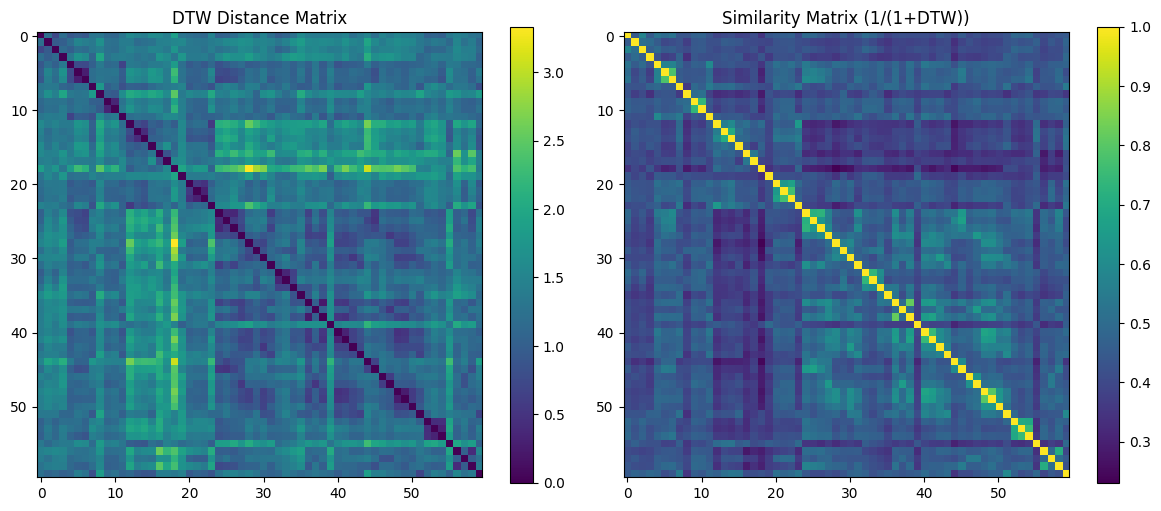

In [ ]:
# Упражнение 1

import numpy as np
import pandas as pd
import urllib.request
import os

# скачиваем Libras с UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/libras/movement_libras.data"
local_path = "movement_libras.data"

if not os.path.exists(local_path):
    print("Скачиваем Libras...")
    urllib.request.urlretrieve(url, local_path)

# загрузка данных
# Libras: первые 90 колонок — временные ряды (X1...X90), последняя — метка класса (1–15)
data = pd.read_csv(local_path, header=None)
X = data.iloc[:, :-1].values.astype(np.float64)  # (360, 90)
y = data.iloc[:, -1].values   # (360,) — метки от 1 до 15

print(f"Форма X: {X.shape}, уникальные классы: {np.unique(y)}")


#  матрица расстояний DTW и матрица сходства
from dtaidistance import dtw
import matplotlib.pyplot as plt
import dtaidistance
print("C-расширения доступны:", dtaidistance.dtw_cc is not None)

# вычисление DTW-матрицы (только для подвыборки из-за сложности O(n²))
# используем первые 60 образцов (4 на класс) для демонстрации
n_subset = 60
indices = []
for cls in np.unique(y):
    idx = np.where(y == cls)[0][:4]  # по 4 образца на класс
    indices.extend(idx)
indices = np.array(indices)[:n_subset]
X_sub = X[indices]
y_sub = y[indices]

print(f"Форма X: {X_sub.shape}, уникальные классы: {np.unique(y_sub)}")


# сортировка по классам для наглядности
sort_idx = np.argsort(y_sub)
X_sub = X_sub[sort_idx]
y_sub = y_sub[sort_idx]

print("Вычисление DTW-матрицы... (может занять 1-2 минуты)")
dtw_matrix = dtw.distance_matrix(X_sub, use_c=False)

# матрица сходства: similarity = 1 / (1 + distance)
similarity_matrix = 1 / (1 + dtw_matrix)

# визуализация
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im1 = axes[0].imshow(dtw_matrix, cmap='viridis')
axes[0].set_title('DTW Distance Matrix')
plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(similarity_matrix, cmap='viridis')
axes[1].set_title('Similarity Matrix (1/(1+DTW))')
plt.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()


# DTW матрица показывает, что диагональные элементы не отличаются друг от друга,
# а также попарное сравнение всех остальных элементов-последовательностей

# матрица сходства показывает, что диагональные элементы не отличаются друг от друга,
# а также попарное сравнение всех остальных элементов-последовательностей,
# видно корректное применение формулы преобразования к матрице DTW (значения распределены от 0.0 до 1.0)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
import time

# разделение на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

results = {}

# классификация SVC
start = time.time()
svc = SVC(kernel='rbf', random_state=42, gamma=1, C=1).fit(X_train, y_train)
train_time = time.time() - start

start = time.time()
y_pred_svc = svc.predict(X_test)
test_time = time.time() - start

results['SVC'] = {
    'acc': accuracy_score(y_test, y_pred_svc),
    'f1': f1_score(y_test, y_pred_svc, average='weighted'),
    'train_time': train_time,
    'test_time': test_time
}

# классификация k-NN
start = time.time()
knn = KNeighborsClassifier(n_neighbors=3).fit(X_train, y_train)
train_time = time.time() - start

start = time.time()
y_pred_knn = knn.predict(X_test)
test_time = time.time() - start

results['k-NN'] = {
    'acc': accuracy_score(y_test, y_pred_knn),
    'f1': f1_score(y_test, y_pred_knn, average='weighted'),
    'train_time': train_time,
    'test_time': test_time
}

for name, res in results.items():
    print(f"{name}\nAcc: {res['acc']:.3f}  F1: {res['f1']:.3f}  Train time: {res['train_time']:.3f}s  Test time: {res['test_time']:.3f}s\n")

SVC
Acc: 0.824  F1: 0.821  Train time: 0.023s  Test time: 0.004s

k-NN
Acc: 0.750  F1: 0.743  Train time: 0.002s  Test time: 0.004s



SVC показала лучшие показатели accuracy и f1-score

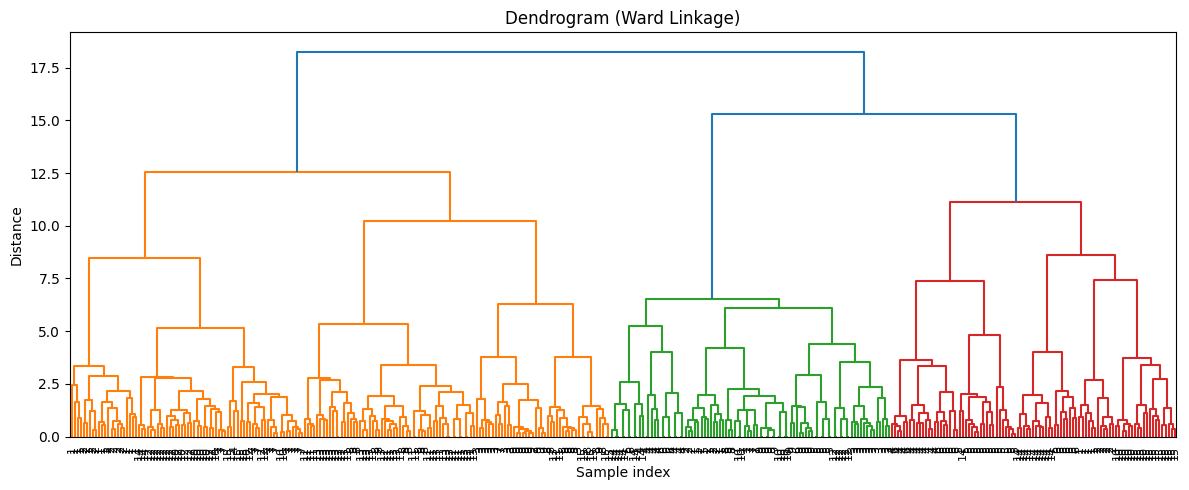

Порог = 2, NMI = 0.693
Число кластеров при t=2: 56


In [ ]:
# иерархическая кластеризация (Linkage Ward)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import v_measure_score
import matplotlib.pyplot as plt

n_subset = 360
indices = []
for cls in np.unique(y):
    idx = np.where(y == cls)[0][:24]  # по 24 образцов на класс
    indices.extend(idx)
indices = np.array(indices)[:n_subset]
X_ward = X[indices]
y_ward = y[indices]

# linkage ward
linkage_matrix = linkage(X_ward, method='ward')

# дендрограмма
plt.figure(figsize=(12, 5))
dendrogram(linkage_matrix, labels=y_ward, leaf_rotation=90, leaf_font_size=8)
plt.title('Dendrogram (Ward Linkage)')
plt.xlabel('Sample index')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()

threshold = 2
clusters = fcluster(linkage_matrix, t=threshold, criterion='distance')

# NMI
nmi = v_measure_score(y_ward, clusters)
print(f"Порог = {threshold}, NMI = {nmi:.3f}")

Оптимальный порог для генерации кластерного раздела - 2, NMI = 0.69

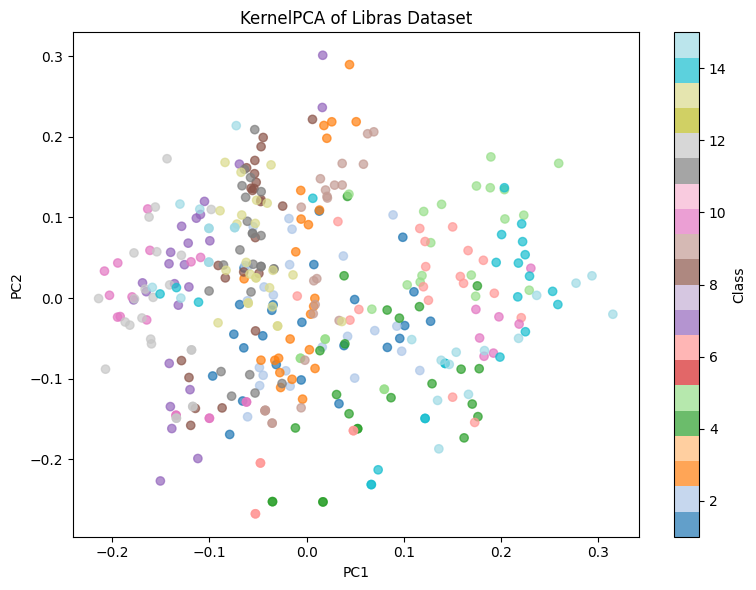

In [ ]:
from sklearn.decomposition import KernelPCA

# KernelPCA
kpca = KernelPCA(n_components=2, kernel='rbf', gamma=0.01, random_state=42)
X_kpca = kpca.fit_transform(X)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_kpca[:, 0], X_kpca[:, 1], c=y, cmap='tab20', alpha=0.7)
plt.colorbar(scatter, label='Class')
plt.title('KernelPCA of Libras Dataset')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.tight_layout()
plt.show()

Снижение размерности не показывает хорошую разделимость кластеров в двухмерном пространстве, разброс в каждом классе довольно большой.

### Упражнение 2

1. Добавьте 40% пропущенных значений к обучающим и тестовым данным.
2. Вычислите ядро ​​TCK.
3. Вычислите матрицу различий из ядра (попробуйте сделать дополнительное к тому, что вы сделали для получения сходства из DTW).

Повторите пункты 4–7 из предыдущего упражнения.

In [ ]:
# Упражнение 2

# добавление пропущенных значений
rng = np.random.RandomState(42)

X_train_miss = X_train.copy().astype(np.float64)
mask_train = rng.rand(*X_train_miss.shape) < 0.4
X_train_miss[mask_train] = np.nan

X_test_miss = X_test.copy().astype(np.float64)
mask_test = rng.rand(*X_test_miss.shape) < 0.4
X_test_miss[mask_test] = np.nan

N_train = X_train_miss.shape[0]
N_test  = X_test_miss.shape[0]

# изменение размерности для TCK
X_train_3d = X_train_miss.reshape(N_train, 45, 2)
X_test_3d  = X_test_miss.reshape(N_test, 45, 2)


from tck.TCK import TCK

G = 10
C = 10

tck = TCK(G, C)
tck.fit(X_train_3d)

K_train = tck.predict(mode='tr-tr')
K_test  = tck.predict(Xte=X_test_3d, mode='tr-te')


if K_test.shape[0] == K_train.shape[0]:
    K_test = K_test.T

# нормировка train-ядра
diag_train = np.sqrt(np.diag(K_train))
K_train_norm = K_train / np.outer(diag_train, diag_train)

# нормировка test-ядра
try:
    K_test_test = tck.predict(Xte=X_test_3d, mode='te-te')
    diag_test = np.sqrt(np.diag(K_test_test))
except Exception:
    diag_test = np.sqrt((K_test ** 2).sum(axis=1) / K_train.shape[0])

K_test_norm = K_test / np.outer(diag_test, diag_train)

# матрица различий
D_train = np.sqrt(np.maximum(0.0, 2.0 - 2.0 * K_train_norm))
np.fill_diagonal(D_train, 0.0)

D_test = np.sqrt(np.maximum(0.0, 2.0 - 2.0 * K_test_norm))

The dataset contains missing data

Training the TCK using the following parameters:
	C = 10, G = 10
	Number of MTS for each GMM: 201 - 252 (80 - 100 percent)
	Number of attributes sampled from [2, 2]
	Length of time segments sampled from [6, 25]




Fitting GMMs:   0%|          | 0/90 [00:00<?, ?it/s]

Computing TCK (tr-tr):   0%|          | 0/90 [00:00<?, ?it/s]

Computing TCK (tr-te):   0%|          | 0/90 [00:00<?, ?it/s]

Computing TCK (te-te):   0%|          | 0/90 [00:00<?, ?it/s]

In [ ]:
from scipy.spatial.distance import squareform

results = {}

# классификация SVC
start = time.time()
svc = SVC(kernel='precomputed', random_state=42, gamma=1, C=1)
svc.fit(K_train_norm, y_train)
train_time = time.time() - start

start = time.time()
y_pred_svc = svc.predict(K_test_norm)
test_time = time.time() - start

results['SVC_TCK'] = {
    'acc': accuracy_score(y_test, y_pred_svc),
    'f1': f1_score(y_test, y_pred_svc, average='weighted'),
    'train_time': train_time,
    'test_time': test_time
}

# классификация k-NN
knn = KNeighborsClassifier(n_neighbors=3, metric='precomputed')

start = time.time()
knn.fit(D_train, y_train)
train_time = time.time() - start

start = time.time()
y_pred_knn = knn.predict(D_test)
test_time = time.time() - start

results['k-NN_TCK'] = {
    'acc': accuracy_score(y_test, y_pred_knn),
    'f1': f1_score(y_test, y_pred_knn, average='weighted'),
    'train_time': train_time,
    'test_time': test_time
}

for name, res in results.items():
    print(f"{name}\nAcc: {res['acc']:.3f}  F1: {res['f1']:.3f}  Train time: {res['train_time']:.3f}s  Test time: {res['test_time']:.3f}s\n")

SVC_TCK
Acc: 0.602  F1: 0.592  Train time: 0.010s  Test time: 0.001s

k-NN_TCK
Acc: 0.611  F1: 0.596  Train time: 0.001s  Test time: 0.004s



K-NN показала лучшие показатели accuracy и f1-score

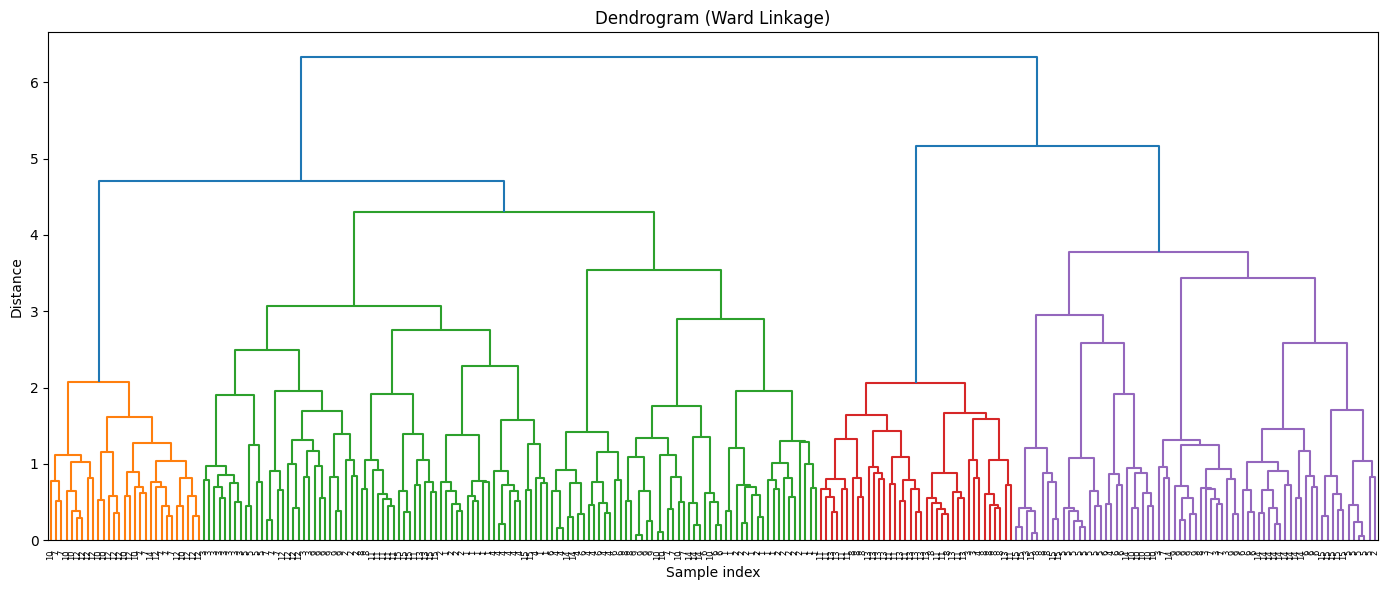

Порог = 1, NMI = 0.684


In [ ]:
condensed = squareform(D_train, checks=False)
Z = linkage(condensed, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(
    Z,
    labels=y_train,
    leaf_rotation=90,
    leaf_font_size=6,
    color_threshold=0.7 * Z[:, 2].max(),
    show_leaf_counts=False,
)
plt.title('Dendrogram (Ward Linkage)')
plt.xlabel('Sample index')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()

threshold = 1
clusters = fcluster(Z, t=threshold, criterion='distance')

nmi = v_measure_score(y_train, clusters)
print(f"Порог = {threshold}, NMI = {nmi:.3f}")

Оптимальный порог для генерации кластерного раздела - 1, NMI = 0.684

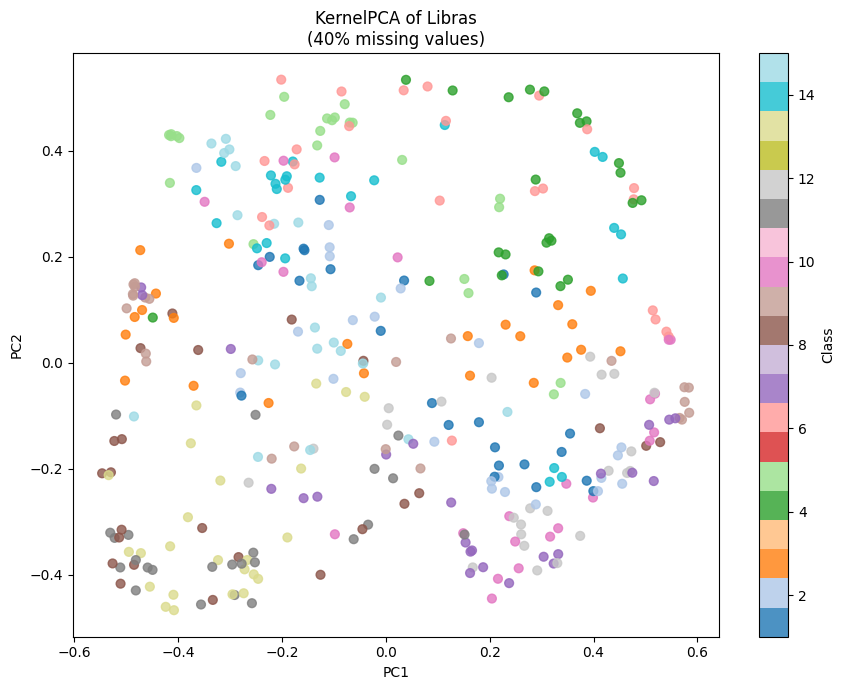

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import KernelPCA

try:
    K_test_test
except NameError:
    K_test_test = tck.predict(Xte=X_test_3d, mode='te-te')

diag_te = np.sqrt(np.diag(K_test_test))
K_test_test_norm = K_test_test / np.outer(diag_te, diag_te)

K_full = np.block([
    [K_train_norm,        K_test_norm.T],
    [K_test_norm,         K_test_test_norm]
])

y_full = np.concatenate([y_train, y_test])

kpca = KernelPCA(
    n_components=2,
    kernel='precomputed',
    random_state=42
)
X_kpca = kpca.fit_transform(K_full)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(
    X_kpca[:, 0], X_kpca[:, 1],
    c=y_full, cmap='tab20', alpha=0.8, s=40
)
plt.colorbar(scatter, label='Class')
plt.title('KernelPCA of Libras\n(40% missing values)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.tight_layout()
plt.show()

Снижение размерности не показывает хорошую разделимость кластеров в двумерном пространстве (хотя некоторые кластеры разделены лучше, чем в 1 упражнении), разброс в каждом классе довольно большой.

### Упражнение 3

1. Вычислите RC-вложения.
2. Получите матрицу сходства и различия из представлений MTS.

Повторите пункты 4–7 из предыдущих упражнений.

In [ ]:
-